## Notebook Description

### Dataset Description
The data includes EV charging reports, Hourly EV charging loads, and idle capacity, for all sessions and users individually along with weather and traffic data of the location.
The datasets are described in the Data In Brief article ["Residential electric vehicle charging datasets from apartment buildings" (2021)](https://www.sciencedirect.com/science/article/pii/S2352340921003899)

### Notebook purpose
- Practice usage of unsupervised learning algorithms:
    - Session-level clustering
    - User-level clustering
    - Anomaly detection

### Workflow
- Environment creation
- Data collection
- Data preparation
- Exploratory Data Analysis
- Feature Engineering
- Model development
- Results

## Step 0: Environment Creation

In [1]:
#%pip install numpy; pandas; matplotlib; seaborn; scikit-learn; kagglehub; hdbscan

In [2]:
import numpy as np
import pandas as pd
import sklearn
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns


c:\D_Folder\GitFiles\DataScienceProjects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1: Data collection

In [3]:
from pathlib import Path

output_dir = Path('datasets')
output_dir.mkdir(exist_ok=True)

path = kagglehub.dataset_download("anshtanwar/residential-ev-chargingfrom-apartment-buildings", output_dir=output_dir)

print("Path to dataset files:", path)

csv_path = output_dir / 'archive'
print("Path to the csv files", csv_path)

Path to dataset files: datasets
Path to the csv files datasets\archive


#### Dataset 1: EV Charging Reports
The CSV file “Dataset 1” describes 6,878 individual charging sessions, registered by 97 user IDs from December 2018 to January 2020.

<details>
<summary>Dataset 1: EV charging reports, describing each individual EV charging session.</summary>

| Column | Description |
|---|---|
| `session_ID` | Unique ID for EV charging session (N=6878) |
| `Garage_ID` | ID for garage address (N=24) |
| `User_ID` | ID for user (N=97) |
| `User_type` | Charging Port (CP) ownership: private or shared CPs |
| `Shared_ID` | ID for shared CP when used (N=12) |
| `Start_plugin` | Plug-in date and time (format: 21.12.2018 10:20) |
| `Start_plugin_hour` | Clock hour for plug-in (00–23) |
| `End_plugout` | Plug-out date and time (format: 21.12.2018 10:20) |
| `End_charging_hour` | Clock hour for plug-out (00–23) |
| `El_kWh` | Charged energy (kWh) |

</details>

In [4]:
df1 = pd.read_csv(csv_path / 'Dataset 1_EV charging reports.csv', sep=';', decimal=',')

df1 = df1.dropna(axis=0, subset=['End_plugout']) #Removed na because it meant the plug-out time is to early compared to energy charged

float_columns = ['Start_plugin_hour', 'End_plugout_hour', 'El_kWh', 'Duration_hours']
timestamp_columns = ['Start_plugin', 'End_plugout']
df1[float_columns] = df1[float_columns].astype(float)
df1[timestamp_columns] = df1[timestamp_columns].apply(
    lambda column: pd.to_datetime(column, format="%d.%m.%Y %H:%M")
)
df1['Shared_ID'] = df1['Shared_ID'].fillna(0)
df1['Shared_ID'] = df1['Shared_ID'].astype('str')

df1.info()

<class 'pandas.DataFrame'>
Index: 6844 entries, 0 to 6877
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   session_ID         6844 non-null   int64         
 1   Garage_ID          6844 non-null   str           
 2   User_ID            6844 non-null   str           
 3   User_type          6844 non-null   str           
 4   Shared_ID          6844 non-null   str           
 5   Start_plugin       6844 non-null   datetime64[us]
 6   Start_plugin_hour  6844 non-null   float64       
 7   End_plugout        6844 non-null   datetime64[us]
 8   End_plugout_hour   6844 non-null   float64       
 9   El_kWh             6844 non-null   float64       
 10  Duration_hours     6844 non-null   float64       
 11  month_plugin       6844 non-null   str           
 12  weekdays_plugin    6844 non-null   str           
 13  Plugin_category    6844 non-null   str           
 14  Duration_category  6844 

#### Conclusions
- Dropped rows with missing End_plugout values since it meant faulty measurements
- Transformed dtype of columns in float and datetime where needed
- filled missing Share_ID(private chg) with 0

#### Dataset 2: Hourly EV charging loads and idle capacity, for all sessions and users individually
The CSV file “Dataset 2” describes EV charging loads and non-charging idle capacity for each user and all EV charging sessions individually.

<details>
<summary>Dataset 2: Hourly EV charging loads and idle capacity, for all users individually.</summary>

| Column | Description |
|---|---|
| `date_from` | Starting time (format: 22.01.2019 19:00) |
| `date_to` | Ending time (format: 22.01.2019 20:00) |
| `User_ID` | ID for user (N=97) |
| `session_ID` | Unique ID for EV charging session (N=6878) |
| `Synthetic_3_6kW` | Synthetic hourly energy load (kWh/h) assuming 3.6 kW charging power (ref. [1]), for users individually |
| `Synthetic_7_2kW` | Synthetic hourly energy load (kWh/h) assuming 7.2 kW charging power (ref. [1]), for users individually |
| `Flex_3_6kW` | Synthetic hourly idle capacity (kWh/h) assuming 3.6 kW charging power, for users individually |
| `Flex_7_2kW` | Synthetic hourly idle capacity (kWh/h) assuming 7.2 kW charging power, for users individually |

</details>

In [5]:
df2 = pd.read_csv(csv_path / 'Dataset 2_Hourly EV loads - Per user.csv', sep=';', decimal=',')
# print(df2.head(15))
# df2.info()

valid_session = df2['session_ID'].notna()
flex_columns = ['Flex_3_6kW', 'Flex_7_2kW']
df2.loc[valid_session, flex_columns] = df2.loc[valid_session, flex_columns].fillna(0)
df2.tail(20)

timestamp_columns = ['date_from', 'date_to']
df2[timestamp_columns] = df2[timestamp_columns].apply(
    lambda column: pd.to_datetime(column, format="%d.%m.%Y %H:%M")
)

# df2_example = df2[df2['session_ID'] == 6862.0]
# df2_example

df2 = df2.fillna(0)
df2['User_ID'] = df2['User_ID'].astype('str')
df2.info()


<class 'pandas.DataFrame'>
RangeIndex: 88156 entries, 0 to 88155
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date_from        88156 non-null  datetime64[us]
 1   date_to          88156 non-null  datetime64[us]
 2   User_ID          88156 non-null  str           
 3   session_ID       88156 non-null  float64       
 4   Synthetic_3_6kW  88156 non-null  float64       
 5   Synthetic_7_2kW  88156 non-null  float64       
 6   Flex_3_6kW       88156 non-null  float64       
 7   Flex_7_2kW       88156 non-null  float64       
dtypes: datetime64[us](2), float64(5), str(1)
memory usage: 5.4 MB


#### Conclusions
- There are NaN values on:
    - UserID, sessionID - it means that at that hour there is no charging happening
    - Synthetic columns - it means that the car is still connected to the charging port but finished charging(0 kW)
    - Flex columns - it means that at that hour there is no charging happening - no idle chg capacity available
- Based on these obervations:
    - Synthetic columns will be filled with 0
    - No charging rows will befilled with 0(this can change based on further processing)

#### Dataset 3: Hourly EV charging loads and idle capacity, aggregated for private or shared CPs
The CSV files “Dataset 3a” and “Dataset 3b” describe EV charging loads and idle capacity, aggregated for users with private (3a) or shared (3b) CPs. Charging power 3.6 kW or 7.2 kW is assumed, with immediate charging after plug-in. 

<details>
<summary>Dataset 3: Hourly EV charging loads and idle capacity, aggregated for private or shared CPs</summary>

| Column | Description |
|---|---|
| `date_from` | Starting time (format: 22.01.2019 19:00) |
| `daily_hour` | Clock hour (00–23) |
| `weekday` | Weekday (Monday–Sunday) |
| `month` | Month (January–December) |
| `Synthetic_3_6kW` | Synthetic hourly energy load (kWh/h) assuming 3.6 kW charging power, aggregated for users with private (2a) or shared (2b) CPs |
| `Synthetic_7_2kW` | Synthetic hourly energy load (kWh/h) assuming 7.2 kW charging power, aggregated for users with private (2a) or shared (2b) CPs |
| `Flex_3_6kW` | Synthetic hourly idle capacity (kWh/h) assuming 3.6 kW charging power, aggregated for users with private (2a) or shared (2b) CPs |
| `Flex_7_2kW` | Synthetic hourly idle capacity (kWh/h) assuming 7.2 kW charging power, aggregated for users with private (2a) or shared (2b) CPs |
| `2a: n_private` | Number of registered User IDs using private CPs (increasing, 1 to 58) |
| `2b: n_shared` | Number of registered User IDs using shared CPs (increasing, 1 to 24) |

</details>

In [6]:
df3a = pd.read_csv(csv_path / 'Dataset 3a_Hourly EV loads - Aggregated private.csv', sep=';', decimal=',')

df3a['date_from'] = pd.to_datetime(df3a['date_from'], format="%d.%m.%Y %H:%M")

print(df3a.head(1))
print(df3a.tail(1))
df3a.info()

            date_from  daily_hour weekday month  Synthetic_3_6kW  \
0 2018-12-21 10:00:00          10  Friday   Dec             1.17   

   Synthetic_7_2kW  Flex_3_6kW  Flex_7_2kW  n_private  
0             1.17         0.0       0.174          1  
               date_from  daily_hour weekday month  Synthetic_3_6kW  \
9756 2020-01-31 22:00:00          22  Friday   Jan              0.0   

      Synthetic_7_2kW  Flex_3_6kW  Flex_7_2kW  n_private  
9756              0.0       1.728       3.456         58  
<class 'pandas.DataFrame'>
RangeIndex: 9757 entries, 0 to 9756
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date_from        9757 non-null   datetime64[us]
 1   daily_hour       9757 non-null   int64         
 2   weekday          9757 non-null   str           
 3   month            9757 non-null   str           
 4   Synthetic_3_6kW  9757 non-null   float64       
 5   Synthetic_7_2kW  97

In [7]:
df3b = pd.read_csv(csv_path / 'Dataset 3b_Hourly EV loads - Aggregated shared.csv', sep=';', decimal=',')

df3b['date_from'] = pd.to_datetime(df3b['date_from'], format="%d.%m.%Y %H:%M")

print(df3b.head())
df3b.info()

            date_from  daily_hour   weekday month  Synthetic_3_6kW  \
0 2019-01-10 00:00:00           0  Thursday   Jan              0.0   
1 2019-01-10 01:00:00           1  Thursday   Jan              0.0   
2 2019-01-10 02:00:00           2  Thursday   Jan              0.0   
3 2019-01-10 03:00:00           3  Thursday   Jan              0.0   
4 2019-01-10 04:00:00           4  Thursday   Jan              0.0   

   Synthetic_7_2kW  Flex_3_6kW  Flex_7_2kW  n_shared  
0              0.0         0.0         0.0         1  
1              0.0         0.0         0.0         1  
2              0.0         0.0         0.0         1  
3              0.0         0.0         0.0         1  
4              0.0         0.0         0.0         1  
<class 'pandas.DataFrame'>
RangeIndex: 9288 entries, 0 to 9287
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date_from        9288 non-null   datetime64

##### Conclusions:
- No missing data in the 3a & 3b columns
- Synthetic+Flex columns that were NaN in df2 are 0 in this dfs
- 3b df starts 20 days later -> less entries
- Later start happens simply because the first shared session starts 20 days later


#### Dataset 4  Dataset 4: Average EV charging loads per user, for each daily hour during weekdays/Saturdays/Sundays 

<details>
<summary>Dataset description</summary>

Dataset 4 in Table 4 shows average EV charging loads per user, for each daily hour during weekdays, Saturdays, and Sundays. Charging power 7.2 kW is assumed, with immediate charg- ing after plug-in. In the table, charging loads for users with private and shared CPs are shown separately. The daily charging load profiles are based on the period with 30 to 82 users, from June 2019 to January 2020, with the number of users with private CPs increasing from 18 to 58, and users with shared CPs increasing from 12 to 24. The subset of the period is chosen, to get a more representative overview of expected power per user for aggregated loads. 

</details>

In [8]:
df4 = pd.read_csv(csv_path / 'Dataset 4_EV_Charging_Loads.csv')

df4.head()
df4.info()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   daily_hour         24 non-null     str    
 1   private_weekdays   24 non-null     float64
 2   private_saturdays  24 non-null     float64
 3   private_sundays    24 non-null     float64
 4   shared_weekdays    24 non-null     float64
 5   shared_saturdays   24 non-null     float64
 6   shared_sundays     24 non-null     float64
dtypes: float64(6), str(1)
memory usage: 1.4 KB


#### Conclusions:
- Dataset is complete, no processing needed

#### Dataset 5: Hourly smart meter data from garage Bl2.
The CSV file “Dataset 5” describes hourly smart meter data from garage Bl2, with aggregated electricity use each hour. The dataset also includes synthetic hourly energy loads, aggregated for the same garage.

<details>
<summary>Column descriptions</summary>

| Column | Description |
|---|---|
| `Garage_ID` | ID for garage address (Bl2) |
| `date_from` | Starting time (format: 22.01.2019 19:00) |
| `date_to` | Ending time (format: 22.01.2019 20:00) |
| `month` | Measurement starting month |
| `AMS_kWh` | Aggregated electricity use in the garage each hour, measured by AMS meter |
| `Synthetic_3_6kW` | Synthetic hourly energy load (kWh/h) assuming 3.6 kW charging power, aggregated for users in the garage |
| `Synthetic_7_2kW` | Synthetic hourly energy load (kWh/h) assuming 7.2 kW charging power, aggregated for users in the garage |
| `Simultaneous_if_3_6kW` | Number of simultaneous charging sessions, assuming all sessions charge with 3.6 kW charging power. NA if no charging sessions are assumed |

</details>

In [9]:
df5 = pd.read_csv(csv_path / 'Dataset 5_AMS data from garage Bl2.csv', sep=';', decimal=',')
#print(df5[df5['date_to'].isna()])
#print(df5.iloc[1500:1510])

timestamp_columns = ['date_from', 'date_to']
df5[timestamp_columns] = df5[timestamp_columns].apply(
    lambda column: pd.to_datetime(column, format="%d.%m.%Y %H:%M")
)

df5.loc[1506, 'date_to'] = '06.03.2019 14:00'
df5.loc[1507, 'date_to'] = '06.03.2019 15:00'

df5.iloc[1500:1515]
df5 = df5.fillna(0)
df5.info()

<class 'pandas.DataFrame'>
RangeIndex: 9466 entries, 0 to 9465
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date_from              9466 non-null   datetime64[us]
 1   date_to                9466 non-null   datetime64[us]
 2   month                  9466 non-null   str           
 3   AMS_kWh                9466 non-null   float64       
 4   Synthetic_3_6kW        9466 non-null   float64       
 5   Synthetic_7_2kW        9466 non-null   float64       
 6   Simultaneous_if_3_6kW  9466 non-null   float64       
dtypes: datetime64[us](2), float64(4), str(1)
memory usage: 517.8 KB


#### Conclusions
- There are missing values in 06.03.2019 at 13:00; 14:00 probably due to an sensor error
- Energy and power for these rows will be set to 0 
- Energy and power for all rows with NA are set to 0 since NA was used if no charging session assumed

#### Dataset 6: Local traffic density
The CSV file “Dataset 6” describes local hourly traffic density in 5 nearby traffic locations, downloaded from [3]. The data includes an hourly count of vehicles shorter than 5.6 meter

<details>
<summary>Dataset 6: Local traffic density </summary>

| Column | Description |
|---|---|
| `Date_from` | Starting time (format: 22.01.2019 19:00) |
| `Date_to` | Ending time (format: 22.01.2019 20:00) |
| `Location 1 to 5` | Number of vehicles shorter than 5.6 meters each hour at five nearby traffic locations |

</details>

In [10]:
df6 = pd.read_csv(csv_path / 'Dataset 6_Local traffic distribution.csv', sep=';', decimal=',')
df6.info()
df6.head()

timestamp_columns = ['Date_from', 'Date_to']
df6[timestamp_columns] = df6[timestamp_columns].apply(
    lambda column: pd.to_datetime(column, format="%d.%m.%Y %H:%M")
)

locations = ['KROPPAN BRU', 'MOHOLTLIA', 'SELSBAKK', 'MOHOLT RAMPE 2', 'Jonsvannsveien vest for Steinanvegen']
datetimes = ['Date_from', 'Date_to']

df6[locations] = df6[locations].replace('-', '0')

df6[locations] = df6[locations].astype(int)
df6[datetimes] = df6[datetimes].apply(
    lambda datetime: pd.to_datetime(datetime, format='%d.%m.%Y %H:%M')
)

df6.info()

<class 'pandas.DataFrame'>
RangeIndex: 10248 entries, 0 to 10247
Data columns (total 7 columns):
 #   Column                                Non-Null Count  Dtype
---  ------                                --------------  -----
 0   Date_from                             10248 non-null  str  
 1   Date_to                               10248 non-null  str  
 2   KROPPAN BRU                           10248 non-null  str  
 3   MOHOLTLIA                             10248 non-null  str  
 4   SELSBAKK                              10248 non-null  str  
 5   MOHOLT RAMPE 2                        10248 non-null  int64
 6   Jonsvannsveien vest for Steinanvegen  10248 non-null  int64
dtypes: int64(2), str(5)
memory usage: 560.6 KB
<class 'pandas.DataFrame'>
RangeIndex: 10248 entries, 0 to 10247
Data columns (total 7 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Date_from           

##### Conclusions
- No missing data in this dataframe
- Converted Date_from and Date_to columns to dataframe
- Converted the rest of the columns from string to int

#### Dataset Weather: Weather for Trondheim

<details>
<summary>Dataset Weather: Weather for Trondheim</summary>

| Column | Description |
|---|---|
| `Unnamed: 0` | Row index included in the CSV; likely not a weather measurement |
| `clouds` | Cloud cover |
| `datetime` | Date of the weather record |
| `dewpt` | Dew-point temperature |
| `dhi` | Diffuse horizontal solar irradiance |
| `dni` | Direct normal solar irradiance |
| `ghi` | Global horizontal solar irradiance |
| `max_dhi` | Maximum diffuse horizontal solar irradiance |
| `max_dni` | Maximum direct normal solar irradiance |
| `max_ghi` | Maximum global horizontal solar irradiance |
| `max_temp` | Maximum temperature |
| `max_temp_ts` | Timestamp for the maximum temperature |
| `max_uv` | Maximum UV index |
| `max_wind_dir` | Wind direction when wind speed was at its maximum |
| `max_wind_spd` | Maximum wind speed |
| `max_wind_spd_ts` | Timestamp for the maximum wind speed |
| `min_temp` | Minimum temperature |
| `min_temp_ts` | Timestamp for the minimum temperature |
| `precip` | Precipitation |
| `precip_gpm` | Precipitation measurement reported as `precip_gpm` in the source data |
| `pres` | Atmospheric pressure |
| `revision_status` | Weather-data revision status |
| `rh` | Relative humidity |
| `slp` | Sea-level pressure |
| `snow` | Snowfall |
| `snow_depth` | Snow depth |
| `solar_rad` | Solar radiation |
| `t_dhi` | Total diffuse horizontal solar irradiance |
| `t_dni` | Total direct normal solar irradiance |
| `t_ghi` | Total global horizontal solar irradiance |
| `t_solar_rad` | Total solar radiation |
| `temp` | Temperature |
| `ts` | Timestamp for the weather record |
| `wind_dir` | Wind direction |
| `wind_gust_spd` | Wind gust speed |
| `wind_spd` | Wind speed |
</details>

In [11]:
df_weather = pd.read_csv(csv_path / 'Norway_Trondheim_ExactLoc_Weather.csv')
print(df_weather[['snow', 'snow_depth']].head(5))
df_weather = df_weather.drop(columns=['Unnamed: 0', 'snow_depth'], errors='ignore')

df_weather['datetime'] = pd.to_datetime(df_weather['datetime'], errors='coerce')
print(df_weather['datetime'].head())
df_weather.info()

    snow  snow_depth
0    0.0         NaN
1    0.0         NaN
2    8.0         NaN
3   37.5         NaN
4  109.5         NaN
0   2018-12-01
1   2018-12-02
2   2018-12-03
3   2018-12-04
4   2018-12-05
Name: datetime, dtype: datetime64[us]
<class 'pandas.DataFrame'>
RangeIndex: 427 entries, 0 to 426
Data columns (total 34 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   clouds           427 non-null    int64         
 1   datetime         427 non-null    datetime64[us]
 2   dewpt            427 non-null    float64       
 3   dhi              427 non-null    int64         
 4   dni              427 non-null    int64         
 5   ghi              427 non-null    int64         
 6   max_dhi          427 non-null    int64         
 7   max_dni          427 non-null    int64         
 8   max_ghi          427 non-null    int64         
 9   max_temp         427 non-null    float64       
 10  max_temp_ts      427 non-n

##### Conclusions
- No missing data apart from snow snow depth feature
- Dropped Unnamed: 0, snow_depth(all nan values and redundant with snow) columns
- Converted datetime column from string to datetime

## Step 2: Feature Engineering

### Create the features

In [12]:
features_columns = ['session_ID', 'Start_plugin', 'End_plugout', 'El_kWh', 'Duration_hours', 'weekdays_plugin']
feature_matrix = df1[features_columns].copy()

feature_matrix['Duration_hours'] = (feature_matrix['End_plugout'] - feature_matrix['Start_plugin']).dt.total_seconds()/3600
feature_matrix.head()

feature_matrix['Start_plugin_frac'] = feature_matrix['Start_plugin'].dt.hour + feature_matrix['Start_plugin'].dt.minute / 60
feature_matrix['End_plugout_frac'] = feature_matrix['End_plugout'].dt.hour + feature_matrix['End_plugout'].dt.minute / 60


feature_matrix['Start_plugin_sin'] = np.sin((2 * np.pi * feature_matrix['Start_plugin_frac'])/24)
feature_matrix['Start_plugin_cos'] = np.cos((2 * np.pi * feature_matrix['Start_plugin_frac'])/24)

feature_matrix['End_plugout_sin'] = np.sin((2 * np.pi * feature_matrix['End_plugout_frac'])/24)
feature_matrix['End_plugout_cos'] = np.cos((2 * np.pi * feature_matrix['End_plugout_frac'])/24)

weekend_days = ['Saturday', 'Sunday']
feature_matrix['Weekend'] = feature_matrix['weekdays_plugin'].isin(weekend_days).astype(int)
feature_matrix['AVG_Power'] = feature_matrix['El_kWh'] / feature_matrix['Duration_hours']

display(feature_matrix.head())
feature_matrix.info()


,session_ID,Start_plugin,End_plugout,El_kWh,Duration_hours,weekdays_plugin,Start_plugin_frac,End_plugout_frac,Start_plugin_sin,Start_plugin_cos,End_plugout_sin,End_plugout_cos,Weekend,AVG_Power
0,1,2018-12-21 10:20:00,2018-12-21 10:23:00,0.30,0.050000,Friday,10.333333,10.383333,0.422618,-0.906308,0.410719,-0.911762,0,6.000000
1,2,2018-12-21 10:24:00,2018-12-21 10:32:00,0.87,0.133333,Friday,10.400000,10.533333,0.406737,-0.913545,0.374607,-0.927184,0,6.525000
2,3,2018-12-21 11:33:00,2018-12-21 19:46:00,29.87,8.216667,Friday,11.550000,19.766667,0.117537,-0.993068,-0.894934,0.446198,0,3.635294
3,4,2018-12-22 16:15:00,2018-12-23 16:40:00,15.56,24.416667,Saturday,16.250000,16.666667,-0.896873,-0.442289,-0.939693,-0.342020,1,0.637270
4,5,2018-12-24 22:03:00,2018-12-24 23:02:00,3.62,0.983333,Monday,22.050000,23.033333,-0.488621,0.872496,-0.250380,0.968148,0,3.681356


<class 'pandas.DataFrame'>
Index: 6844 entries, 0 to 6877
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   session_ID         6844 non-null   int64         
 1   Start_plugin       6844 non-null   datetime64[us]
 2   End_plugout        6844 non-null   datetime64[us]
 3   El_kWh             6844 non-null   float64       
 4   Duration_hours     6844 non-null   float64       
 5   weekdays_plugin    6844 non-null   str           
 6   Start_plugin_frac  6844 non-null   float64       
 7   End_plugout_frac   6844 non-null   float64       
 8   Start_plugin_sin   6844 non-null   float64       
 9   Start_plugin_cos   6844 non-null   float64       
 10  End_plugout_sin    6844 non-null   float64       
 11  End_plugout_cos    6844 non-null   float64       
 12  Weekend            6844 non-null   int64         
 13  AVG_Power          6844 non-null   float64       
dtypes: datetime64[us](2), fl

### Deal with the skewness of numeric columns

c:\D_Folder\GitFiles\DataScienceProjects\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,session_ID,Start_plugin,End_plugout,El_kWh,Duration_hours,Start_plugin_frac,End_plugout_frac,Start_plugin_sin,Start_plugin_cos,End_plugout_sin,End_plugout_cos,Weekend,AVG_Power
count,6844.000000,6844,6844,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000
mean,3430.309614,2019-10-01 01:51:57.448860,2019-10-01 13:22:09.827586,12.727582,11.503439,16.818617,13.046778,-0.625156,-0.053846,-0.028688,-0.297852,0.263881,inf
min,1.000000,2018-12-21 10:20:00,2018-12-21 10:23:00,0.010000,0.000000,0.000000,0.033333,-1.000000,-1.000000,-1.000000,-1.000000,0.000000,0.000559
25%,1711.750000,2019-08-04 15:45:15,2019-08-04 18:50:30,5.217500,2.783333,15.133333,7.900000,-0.938191,-0.591310,-0.845728,-0.763232,0.000000,0.629898
50%,3422.500000,2019-11-01 23:43:00,2019-11-02 17:05:00,9.055000,10.016667,17.066667,12.450000,-0.811574,-0.156434,-0.095846,-0.378649,0.000000,1.514136
75%,5139.250000,2019-12-18 18:21:45,2019-12-19 07:25:30,16.070000,15.216667,19.850000,17.616667,-0.477159,0.530843,0.866025,-0.039260,1.000000,3.519430
max,6878.000000,2020-01-31 20:42:00,2020-01-31 23:53:00,80.860000,255.033333,23.983333,23.983333,1.000000,1.000000,1.000000,0.999990,1.000000,inf
std,1986.246818,NaN,NaN,11.794003,14.146048,4.366184,5.254927,0.452117,0.634002,0.777154,0.553738,0.440768,NaN


113 zero-duration sessions
142 under 1 kWh sessions
108 sessions above 7.2 kW
53 sessions longer than 3 days


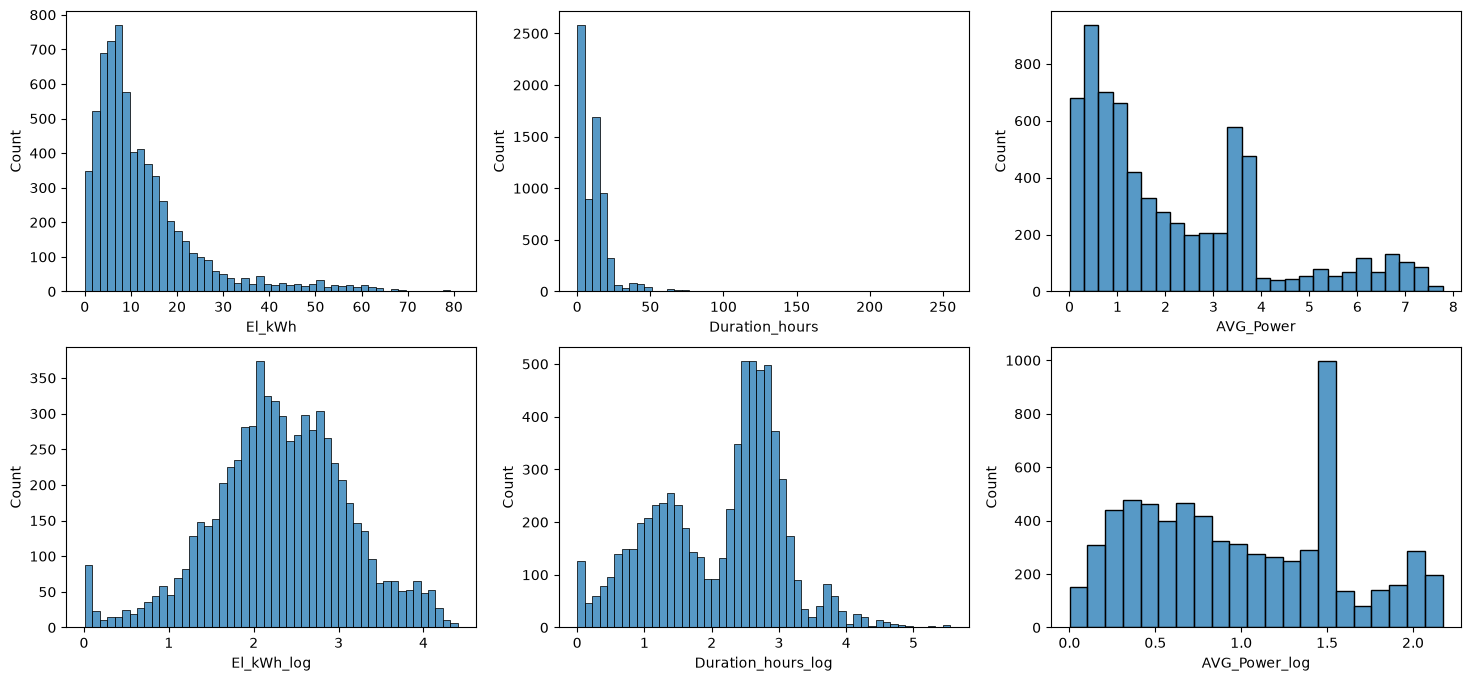

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

sns.histplot(data=feature_matrix, x='El_kWh', bins=50, ax=axes[0][0])
sns.histplot(data=feature_matrix, x='Duration_hours', bins=50, ax=axes[0][1])
sns.histplot(data=feature_matrix, x='AVG_Power', ax=axes[0][2])

display(feature_matrix.describe())

feature_matrix['Duration_hours_log'] = np.log1p(feature_matrix['Duration_hours'])
feature_matrix['El_kWh_log'] = np.log1p(feature_matrix['El_kWh'])
feature_matrix['AVG_Power_log'] = np.log1p(feature_matrix['AVG_Power'])

sns.histplot(data=feature_matrix, x='El_kWh_log', bins=50, ax=axes[1][0])
sns.histplot(data=feature_matrix, x='Duration_hours_log', bins=50, ax=axes[1][1])
sns.histplot(data=feature_matrix, x='AVG_Power_log', ax=axes[1][2])


print((feature_matrix["Duration_hours"] < 0.1).sum(), "zero-duration sessions")
print((feature_matrix["El_kWh"] < 0.5).sum(), "under 1 kWh sessions")
print((feature_matrix["AVG_Power"] > 7.2).sum(), "sessions above 7.2 kW")
print((feature_matrix["Duration_hours"] > 72).sum(), "sessions longer than 3 days")

#Eliminate rows with duration hours == 0
feature_matrix = feature_matrix[feature_matrix["Duration_hours"] > 0]


### Flag long duration hours and deal with almost 0 hours charging

0.10     1.183333
0.25     2.816667
0.50    10.066667
0.75    15.241667
0.90    20.823333
Name: Duration_hours, dtype: float64


<Axes: xlabel='AVG_Power_log', ylabel='Count'>

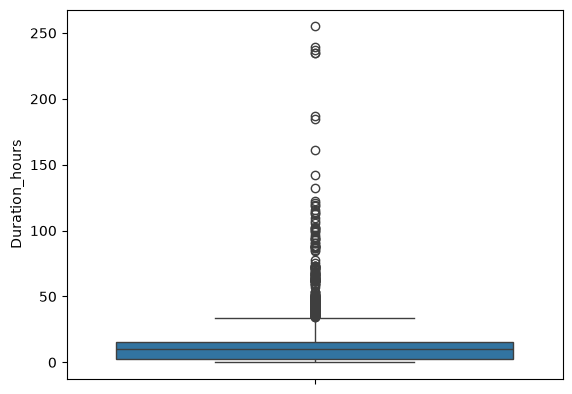

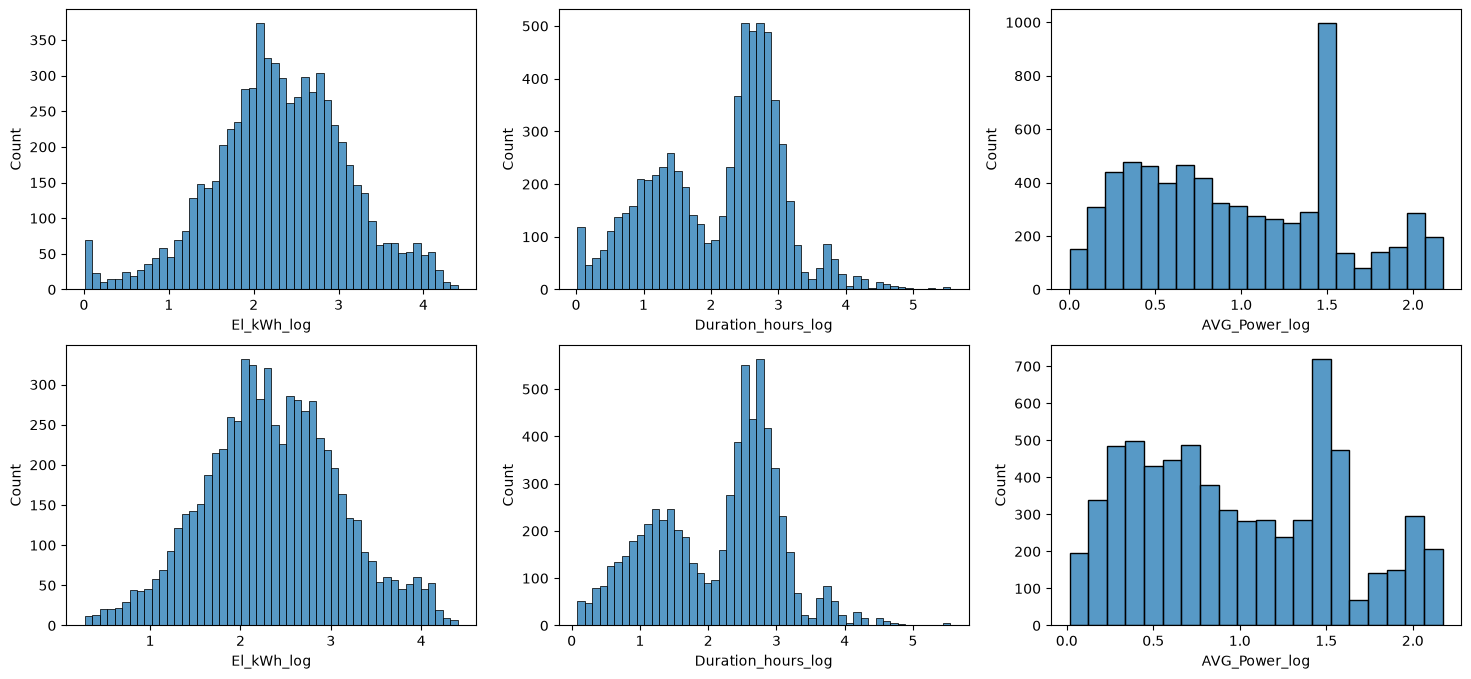

In [14]:
#Step 1: Long duration chargings flagging
sns.boxplot(data=feature_matrix, y='Duration_hours')

duration_hours = feature_matrix['Duration_hours']

percentiles = duration_hours.quantile([0.1, 0.25, 0.5, 0.75, 0.9])

print(percentiles)
q1 = percentiles.loc[0.25]
q3 = percentiles.loc[0.75]

iqr = q3 - q1
upper_extreme = q3 + iqr * 1.5

#Since upper extreme is around 33 hours(almost equal to a day and a half), this will be used as flagging threshold
feature_matrix['Duration_flag'] = (feature_matrix['Duration_hours'] <= upper_extreme).astype(int)
feature_matrix.head()

#Step 2: Too short chargings delete 

fig, axes = plt.subplots(2, 3, figsize=(18, 8))

sns.histplot(data=feature_matrix, x='El_kWh_log', bins=50, ax=axes[0][0])
sns.histplot(data=feature_matrix, x='Duration_hours_log', bins=50, ax=axes[0][1])
sns.histplot(data=feature_matrix, x='AVG_Power_log', ax=axes[0][2])

low_duration_threshold = 0.083 #5 minutes
low_energy_threshold = 0.3 # 5 mins of charging at 3.6 kW
feature_matrix = feature_matrix[(feature_matrix['Duration_hours']>low_duration_threshold) & (feature_matrix['El_kWh']>low_energy_threshold)]

sns.histplot(data=feature_matrix, x='El_kWh_log', bins=50, ax=axes[1][0])
sns.histplot(data=feature_matrix, x='Duration_hours_log', bins=50, ax=axes[1][1])
sns.histplot(data=feature_matrix, x='AVG_Power_log', ax=axes[1][2])


### Create a df only with the features that will be used in clustering. (Discard helper features)

In [ ]:
from sklearn.preprocessing import StandardScaler

useful_features = ['Start_plugin_sin', 'Start_plugin_cos',
                   'End_plugout_sin', 'End_plugout_cos',
                   'Weekend',
                   'Duration_hours_log', 'El_kWh_log', 'AVG_Power_log']

X = feature_matrix[useful_features]
X_scaled = StandardScaler().fit_transform(X)

j = useful_features.index("Weekend")
X_w = X_scaled.copy()
X_w[:, j] *= 0.5


4


## Step 3: Clustering

### Step 3.1: K-Means Clustering

,k,inertia,silhouette,davies_bouldin
0,2,32933.809987,0.308600,1.455417
1,3,27579.207557,0.317285,1.328618
2,4,23697.618777,0.235507,1.611148
3,5,21474.135729,0.204434,1.659790
4,6,19364.182056,0.201509,1.632247
5,7,18027.516019,0.198197,1.647788
6,8,16965.747684,0.192307,1.610933
7,9,15971.289541,0.192667,1.591032
8,10,15234.468764,0.191708,1.579727


Stability across seeds is: 0.9993497149343457


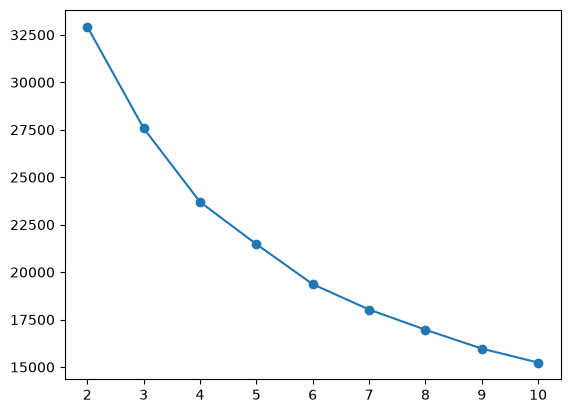

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score

results = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, n_init=8, random_state=42)
    labels = kmeans.fit_predict(X_w)
    results.append({
        'k': k,
        'inertia': kmeans.inertia_,
        'silhouette': silhouette_score(X_scaled, labels, sample_size=3000, random_state=42),
        'davies_bouldin': davies_bouldin_score(X_scaled, labels)
    })

df_results = pd.DataFrame(results)
plt.plot(df_results['k'], df_results['inertia'], marker='o')
display(df_results)

k=3
runs = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X_scaled)
        for s in range(10)]

scores = [adjusted_rand_score(runs[0], r) for r in runs[1:]]
print(f'Stability across seeds is: {sum(scores) / len(scores)}')


#### Conclusions:
- Silhouette peaks at k=3 (0.320), with k=2 close behind (0.308). It then falls to about 0.21 to 0.24 for k≥5.
- Davies-Bouldin is lowest at k=3 (1.351), which agrees with the silhouette. Both signals pointing at the same k is what you want.
- Inertia falls smoothly with no sharp elbow. There’s a mild bend around k=3 to 4, but the elbow alone wouldn’t give a clear answer.
- Stability across multiple random seeds is > 99% -> Results are stable for both k=3 and k=4

In [29]:
df = feature_matrix.copy()
for k in [3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    df[f"cluster_k{k}"] = km.fit_predict(X_w)

profile_cols = ['Start_plugin_frac', 'End_plugout_frac',
                'Duration_hours',
                'El_kWh', 'AVG_Power']


def profile(df, label_col):
    g = df.groupby(label_col)
    table = g[profile_cols].median().round(2)
    table['size'] = g.size()
    table["share_%"] = (table["size"] / len(df) * 100).round(1)
    table["weekend_%"] = (g["Weekend"].mean() * 100).round(1)

    return table

k3 = profile(df, "cluster_k3")
k4 = profile(df, "cluster_k4")

display(df.head())
display(k3)
display(k4)

pd.crosstab(df["cluster_k3"], df["cluster_k4"])


,session_ID,Start_plugin,End_plugout,El_kWh,Duration_hours,weekdays_plugin,Start_plugin_frac,End_plugout_frac,Start_plugin_sin,Start_plugin_cos,End_plugout_sin,End_plugout_cos,Weekend,AVG_Power,Duration_hours_log,El_kWh_log,AVG_Power_log,Duration_flag,cluster_k3,cluster_k4
1,2,2018-12-21 10:24:00,2018-12-21 10:32:00,0.87,0.133333,Friday,10.400000,10.533333,0.406737,-0.913545,0.374607,-0.927184,0,6.525000,0.125163,0.625938,2.018231,1,0,2
2,3,2018-12-21 11:33:00,2018-12-21 19:46:00,29.87,8.216667,Friday,11.550000,19.766667,0.117537,-0.993068,-0.894934,0.446198,0,3.635294,2.221013,3.429785,1.533700,1,0,2
3,4,2018-12-22 16:15:00,2018-12-23 16:40:00,15.56,24.416667,Saturday,16.250000,16.666667,-0.896873,-0.442289,-0.939693,-0.342020,1,0.637270,3.235405,2.806990,0.493030,1,1,3
4,5,2018-12-24 22:03:00,2018-12-24 23:02:00,3.62,0.983333,Monday,22.050000,23.033333,-0.488621,0.872496,-0.250380,0.968148,0,3.681356,0.684779,1.530395,1.543588,1,2,0
5,6,2018-12-24 23:32:00,2018-12-25 17:37:00,16.14,18.083333,Monday,23.533333,17.616667,-0.121869,0.992546,-0.994969,-0.100188,0,0.892535,2.948815,2.841415,0.637917,1,1,1


,Start_plugin_frac,End_plugout_frac,Duration_hours,El_kWh,AVG_Power,size,share_%,weekend_%
cluster_k3,,,,,,,,
0,11.06,14.32,3.14,7.62,3.26,828,12.3,36.7
1,18.98,8.33,14.45,11.55,0.78,3835,57.1,26.1
2,16.42,18.88,2.33,6.90,3.56,2056,30.6,23.4


,Start_plugin_frac,End_plugout_frac,Duration_hours,El_kWh,AVG_Power,size,share_%,weekend_%
cluster_k4,,,,,,,,
0,16.42,18.90,2.33,6.90,3.56,2037,30.3,23.1
1,20.50,7.90,11.55,18.67,1.58,1669,24.8,26.3
2,11.22,14.44,2.95,7.48,3.38,798,11.9,36.2
3,17.48,9.55,16.72,7.52,0.44,2215,33.0,26.5


cluster_k4,0,1,2,3
cluster_k3,,,,
0,0,27,782,19
1,0,1638,3,2194
2,2037,4,13,2


#### Conclusions

- Using k=3 the resulting clusters are:
    - k=0 - Midday charge - lowest share 12%(people are at work at that time) -> higher weekend share than the rest
    - k=1 - After work charge - has 31% share
    - k=2 - Overnight charge - has 57% share; low AVG Power -> high idle time
- Using k=4 the extra cluster splits the overnight charge into weekdays vs weekends + lower metrics signifies that it is not relevant

### Compare the results between using all data and using data without long duration stays


In [30]:
def fit_k3(df, cols):
    X = StandardScaler().fit_transform(df[cols])
    return KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)

subset = feature_matrix[feature_matrix['Duration_flag'] == 1]

labels_full = pd.Series(fit_k3(feature_matrix, useful_features), index=feature_matrix.index)
labels_sub = pd.Series(fit_k3(subset, useful_features), index = subset.index)

print(adjusted_rand_score(labels_full.loc[subset.index], labels_sub))

0.9940680484070192


#### Conclusion

- Because the score is almost 1 -> the long stays don't change the clusters

### Step 3.2 HDBSCAN Model

In [31]:
import hdbscan

rows = []

min_cluster_sizes = [20, 30, 50, 100, 200]
min_samples = [5, 10, 30]

for mcs in min_cluster_sizes:
    for ms in min_samples:
        label = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit_predict(X_w)
        mask = labels != -1
        n_clusters = len(set(label[mask]))
        silhouette = (silhouette_score(X_scaled[mask], label[mask]) if n_clusters > 1 else None)
        rows.append({
            "min_cluster_size": mcs,
            "min_samples": ms,
            "n_clusters": n_clusters,
            "noise_%": round((~mask).mean()*100, 1),
            "silhouette_non_noise": silhouette
        })
results_hdb = pd.DataFrame(rows)
display(results_hdb)



,min_cluster_size,min_samples,n_clusters,noise_%,silhouette_non_noise
0,20,5,9,0.0,0.084606
1,20,10,7,0.0,0.151542
2,20,30,5,0.0,0.179913
3,30,5,7,0.0,0.111786
4,30,10,5,0.0,0.231820
5,30,30,5,0.0,0.179913
6,50,5,6,0.0,0.136994
7,50,10,5,0.0,0.231820
8,50,30,5,0.0,0.179913
9,100,5,5,0.0,0.233026


In [32]:
df_hdb = feature_matrix.copy()

labels_test = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=5)
df_hdb[f"cluster_mcs_200_ms_5"] = labels_test.fit_predict(X_w)

hdb_best = profile(df_hdb, 'cluster_mcs_200_ms_5')

display(hdb_best)


,Start_plugin_frac,End_plugout_frac,Duration_hours,El_kWh,AVG_Power,size,share_%,weekend_%
cluster_mcs_200_ms_5,,,,,,,,
-1,13.48,12.99,19.77,9.20,0.63,408,6.1,63.7
0,16.00,18.02,2.35,6.79,3.54,2018,30.0,0.0
1,19.23,8.12,13.92,11.63,0.81,2768,41.2,0.0
2,18.32,9.28,14.87,11.46,0.79,863,12.8,100.0
3,15.16,17.78,2.59,8.02,3.56,662,9.9,100.0


#### Conclusions
- Clusters found by the hdbscan alg do not offer same interpretable result
- Similar structure with KMeans is still present
- The following clusters are present:
    - Noise(-1) - has almost 1 day duration with low total and weekend share
    - 0 - 10 duration hours(seems wrong calculation) with quarter total share and 100% weekend share
    - 1 - small duration hours(after work) with okay average power only on weekdays
    - 2 - long duration hours(overnight) with small average power only on weekdays

### Step 3.3 GMM(Gaussian Mixture Model)

In [ ]:
from sklearn.mixture import GaussianMixture

rows = []

for k in range(2, 11):
    gmm = GaussianMixture(
        n_components=k, 
        covariance_type='full',
        n_init=5,
        random_state=42,
    )
    labels = gmm.fit_predict(X_w)

    rows.append({
        'k': k,
        'bic': gmm.bic(X_scaled),
        'aic': gmm.aic(X_scaled),
        'silhouette': silhouette_score(X_scaled, labels, sample_size=3000, random_state=42)
    })

gmm_results = pd.DataFrame(rows)
display(gmm_results)


,k,bic,aic,silhouette
0,2,113495.449020,112889.119200,0.307028
1,3,88539.577093,87626.676015,0.205397
2,4,79700.826251,78481.353916,0.150544
3,5,68487.336509,66961.292916,0.108070
4,6,61790.061726,59957.446875,0.107717
5,7,53921.119986,51781.933877,0.101913
6,8,51009.921478,48564.164112,0.110372
7,9,45934.373135,43182.044511,0.099940
8,10,42895.942934,39837.043053,0.102233


#### Conclusions

- BIC and AIC keep improvinb but irregurarly because:
    - features are skewed(are not gaussian)
    - some values are discrete(updating "Weekend" scaling helped)
- Silhouette score results
    - k=[2, 3] are the best results but still inferior to KMeans
    - k settles at around 0.1 which means almost no separation
- Final result - the signals disagree slightly
    - silhouette favors k=2(k=3 is acceptable)
    - BIC biggest gain is at k=3



In [24]:
gmm = GaussianMixture(n_components=3, covariance_type="full", reg_covar=1e-2, n_init=10, random_state=42)
df["cluster_gmm"] = gmm.fit_predict(X_scaled)
print(pd.crosstab(df["cluster_k3"], df["cluster_gmm"]))
print(adjusted_rand_score(df["cluster_k3"], df["cluster_gmm"]))

cluster_gmm    0     1     2
cluster_k3                  
0             69    52   736
1            995  2840     0
2             13     8  2006
0.5703495666475393
